# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:**
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.titlesize': 13
})

clean = pd.read_parquet("clean_data.parquet")
campaign = pd.read_csv("campaign_list.csv")
cleaning_log = pd.read_csv("cleaning_log.csv")

## 1. Главное

1. **Системное падение денежного оборота с января 2025 года:** среднемесячный объем трат клиентов в первом полугодии 2025 года (H1) снизился на **21.4%** по сравнению с базовым периодом 2024 года (падение с 63.8 млн до 50.1 млн руб./мес.). Точка перегиба — январь 2025 года, после которого оборот не вернулся к норме.
2. **Основной денежный ущерб сосредоточен в «Массовом» сегменте:** траты клиентов Массового сегмента сократились на **31.2%** (в абсолюте сегмент потерял до 8 млн руб./мес. в пиковые месяцы), тогда как спад по Зарплатному (-9.5%) и Премиальному (-11.8%) сегментам оказался значительно мягче.
3. **«Усыхание» корзины трат вместо закрытия карт:** доля клиентов, полностью прекративших операции более чем на 90 дней, составляет всего **1.5% (86 чел.)**, а ушедших в полный ноль за 180 дней — **0.16% (7 чел.)**. Клиенты сохранили карты, но перенаправили основные денежные потоки в другие банки.
4. **Сформирована кампания на 1 977 клиентов под бюджет 2 000 мест:** выделены 4 непересекающиеся группы с персональными офферами (от 218 до 723 чел., все $\ge 150$). Кампания охватывает только клиентов с действующим согласием на коммуникацию.

## 2. Контекст

Департамент розничных продуктов банка «Меридиан» зафиксировал снижение частоты и объемов использования банковских карт в первой половине 2025 года. Цель настоящего исследования — выявить точные клиентские сегменты и поведенческие паттерны, сформировавшие просадку, определить ключевые драйверы падения и сформировать таргетированный список клиентов для кампании по реактивации. 

Кампания ограничена жестким бюджетом в **2 000 уникальных клиентов** и требует разделения на 3–5 содержательных групп (не менее 150 человек в каждой) с персональным ценностным предложением под каждую причину снижения трат.

## 3. Данные и ограничения

Анализ проведен на данных за период с **01.01.2024 по 30.06.2025** (18 месяцев). Базовым периодом для оценки нормы поведения принят **2024 год** (12 месяцев), оцениваемым периодом — **первое полугодие 2025 года** (H1, 6 месяцев). 

Из исходного массива исключены: технические дубликаты (1 500 транзакций и 42 записи клиентов), 24 строки с неустранимым конфликтом атрибутов в CRM, 76 транзакций вне окон исследования и 30 810 операций по закрытым счетам. Несостоявшиеся операции (`отклонено`) и валютные операции сохранены для оценки причин оттока. Итоговая очищенная база охватывает **5 626 действующих клиентов** и **594 950 операций**.

**Выбор метрики активности:**  
В качестве основной метрики выбрано **относительное изменение среднемесячной суммы успешных трат** ($drop\_sum\_pct$) между первыми полугодиями 2024 и 2025 годов. Сумма трат напрямую определяет комиссионный доход банка от эквайринга/интерчейнджа.  
*Что метрика не видит:* метрика чувствительна к крупным разовым покупкам (например, приобретение бытовой техники в 2024 году создает иллюзию обвала в 2025-м) и не фиксирует «измельчание» чеков, если общая сумма сохранилась за счет редких крупных платежей (например, оплаты ЖКУ или кредита).

**Ограничения данных:** В выгрузке отсутствуют остатки на счетах и вкладах (невозможно отличить перевод средств на накопительный счет от ухода денег из банка), нет данных по программам кэшбэка банков-конкурентов и самого банка "Меридиан", нет логов обращений в службу поддержки.

In [3]:
# Краткая витрина объема данных
summary_table = pd.DataFrame([{
    "Действующих клиентов": f"{clean['client_id'].nunique():,}",
    "Всего операций": f"{len(clean):,}",
    "Период": "01.01.2024 — 30.06.2025",
    "Суммарный оборот (H1 2024)": f"{clean[(clean['txn_datetime'] >= '2024-01-01') & (clean['txn_datetime'] <= '2024-06-30') & (clean['status'] != 'отклонено')]['amount'].sum() / 1e6:.1f} млн руб.",
    "Суммарный оборот (H1 2025)": f"{clean[(clean['txn_datetime'] >= '2025-01-01') & (clean['txn_datetime'] <= '2025-06-30') & (clean['status'] != 'отклонено')]['amount'].sum() / 1e6:.1f} млн руб."
}])
display(summary_table)

,Действующих клиентов,Всего операций,Период,Суммарный оборот (H1 2024),Суммарный оборот (H1 2025)
0,"5,615","594,950",01.01.2024 — 30.06.2025,353.1 млн руб.,294.6 млн руб.


## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Обвал оборота начался скачкообразно в январе 2025 года и закрепился на уровне -21%
После традиционного предновогоднего пика в декабре 2024 года (84 млн руб.) суммарные траты клиентов в январе 2025 упали до рекордных 39.5 млн руб. и в последующие месяцы не восстановились до базовых значений 2024 года (удерживаясь на уровне 46–57 млн руб./мес.).

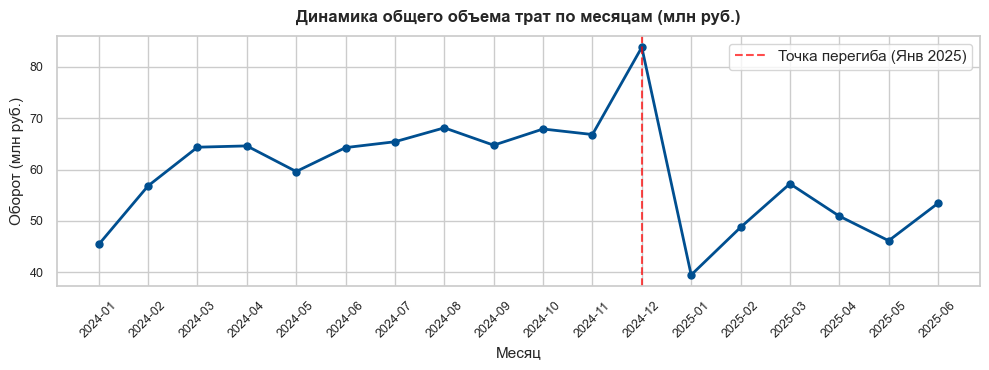

In [4]:
clean['year_month'] = clean['txn_datetime'].dt.to_period('M')
m_dyn = clean[clean['status'] != 'отклонено'].groupby('year_month')['amount'].sum().reset_index()
m_dyn['year_month_str'] = m_dyn['year_month'].astype(str)

plt.figure(figsize=(10, 3.8))
plt.plot(m_dyn['year_month_str'], m_dyn['amount'] / 1e6, marker='o', color='#004f90', linewidth=2, markersize=5)
plt.title('Динамика общего объема трат по месяцам (млн руб.)', fontweight='bold', pad=10)
plt.xlabel('Месяц')
plt.ylabel('Оборот (млн руб.)')
plt.xticks(rotation=45)
plt.axvline('2024-12', color='red', linestyle='--', alpha=0.7, label='Точка перегиба (Янв 2025)')
plt.legend()
plt.tight_layout()
plt.show()

### 4.2. Львиная доля выпадающего оборота приходится на клиентов «Массового» сегмента
В деньгах главный удар по банку нанес «Массовый» сегмент: если весной 2024 года его ежемесячный оборот стабильно превышал 24 млн руб., то в H1 2025 года он просел до 16–18 млн руб. (падение на 6–8 млн руб./мес.). При этом состоятельный сегмент Private показал минимальные колебания, а Зарплатный сегмент сохранил устойчивость ядра трат.

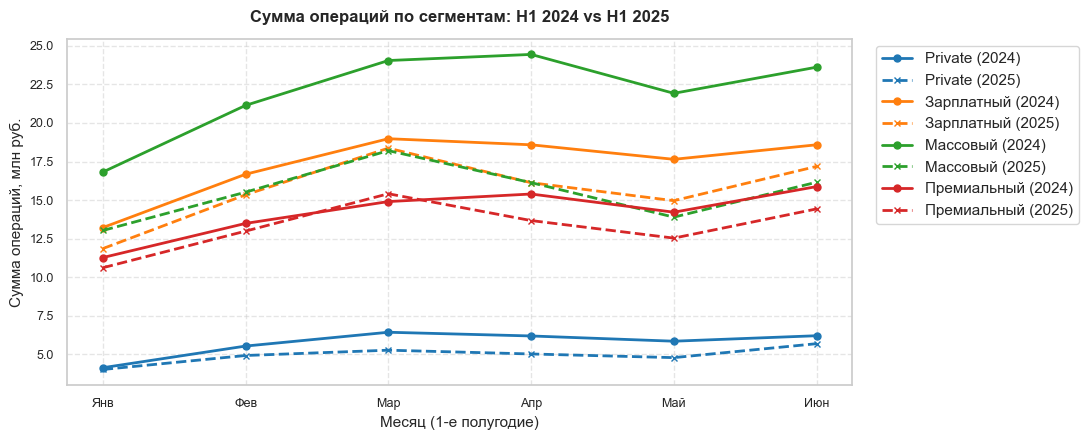

In [8]:
# Фильтруем данные за 1-е полугодия 2024 и 2025 гг.
h1 = clean[(clean['txn_datetime'].dt.month <= 6) & (clean['status'] != 'отклонено')].copy()
h1['year'] = h1['txn_datetime'].dt.year.astype(str)
h1['month_num'] = h1['txn_datetime'].dt.month

# Агрегируем СУММУ операций по месяцам и сегментам
seg_monthly_sum = h1.groupby(['year', 'segment', 'month_num'])['amount'].sum().reset_index()
seg_monthly_sum['amount_mln'] = seg_monthly_sum['amount'] / 1e6

month_names = {1: 'Янв', 2: 'Фев', 3: 'Мар', 4: 'Апр', 5: 'Май', 6: 'Июн'}
seg_monthly_sum['month_name'] = seg_monthly_sum['month_num'].map(month_names)

# Порядок месяцев и сегментов
months_order = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн']
segments_order = ['Private', 'Зарплатный', 'Массовый', 'Премиальный']
colors = {'Private': '#1f77b4', 'Зарплатный': '#ff7f0e', 'Массовый': '#2ca02c', 'Премиальный': '#d62728'}

plt.figure(figsize=(11, 4.5))

for seg in segments_order:
    # 2024 (сплошная линия)
    d24 = seg_monthly_sum[(seg_monthly_sum['segment'] == seg) & (seg_monthly_sum['year'] == '2024')].sort_values('month_num')
    plt.plot(d24['month_name'], d24['amount_mln'], marker='o', label=f"{seg} (2024)", 
             color=colors[seg], linewidth=2, markersize=5)
    
    # 2025 (пунктирная линия)
    d25 = seg_monthly_sum[(seg_monthly_sum['segment'] == seg) & (seg_monthly_sum['year'] == '2025')].sort_values('month_num')
    plt.plot(d25['month_name'], d25['amount_mln'], marker='x', linestyle='--', label=f"{seg} (2025)", 
             color=colors[seg], linewidth=2, markersize=5)

plt.title('Сумма операций по сегментам: H1 2024 vs H1 2025', fontweight='bold', pad=12)
plt.xlabel('Месяц (1-е полугодие)')
plt.ylabel('Сумма операций, млн руб.')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

## 5. Группы для кампании

На основе выявленных драйверов оттока отобраны **4 целевые группы** суммарной численностью **1 977 клиентов** (бюджетный лимит: 2 000).  
Применен принцип каскадного непересекающегося отбора (Waterfall): клиент распределяется в первую подходящую группу и исключается из последующих.

| Группа | Правило отбора (Кто это) | Характер падения (Что произошло) | Размер | Рекомендуемая коммуникация / Оффер |
|:---|:---|:---|:---:|:---|
| **1. Зарплата в другом банке** | `income_source == 'Зарплата в другом банке'` | Падение суммы трат $> 20\%$ | **723** | Персональный кэшбэк 5% на категорию «Продукты» при регулярном переводе части дохода через СБП. |
| **2. Без приложения** | `has_mobile_app == 'Нет'` | Падение суммы трат $> 40\%$ | **584** | SMS/Viber-коммуникация с прямой ссылкой на приложение и гарантированным бонусом 500 ₽ за первый вход. |
| **3. Цифровая спячка** | `has_mobile_app == 'Да'`, нет логина $> 6$ мес. | Падение суммы трат $> 40\%$ | **452** | Push/звонок с реактивационным промокодом на маркетплейсы/онлайн-сервисы при оплате картой. |
| **4. Массовый дебет** | Сегмент `Массовый` с дебетовыми картами | Падение суммы трат $> 30\%$ | **218** | Отмена платы за СМС-информирование и повышенный кэшбэк на транспорт/аптеки на 3 месяца. |

C:\Users\User\AppData\Local\Temp\ipykernel_8972\2849716644.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=campaign, y='group', palette='crest', order=campaign['group'].value_counts().index)


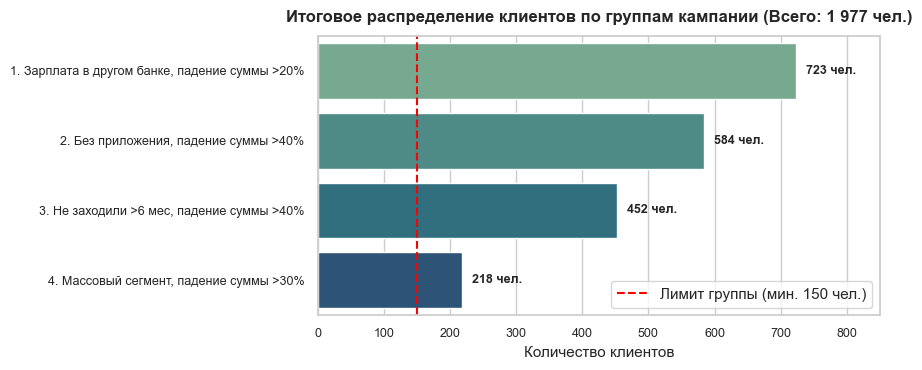

In [6]:
plt.figure(figsize=(9, 3.8))
ax = sns.countplot(data=campaign, y='group', palette='crest', order=campaign['group'].value_counts().index)
plt.title('Итоговое распределение клиентов по группам кампании (Всего: 1 977 чел.)', fontweight='bold', pad=10)
plt.xlabel('Количество клиентов')
plt.ylabel('')
plt.axvline(150, color='red', linestyle='--', label='Лимит группы (мин. 150 чел.)')
plt.legend(loc='lower right')

for p in ax.patches:
    ax.annotate(f"{int(p.get_width()):,} чел.", (p.get_width() + 15, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=9, fontweight='bold')

plt.xlim(0, 850)
plt.tight_layout()
plt.show()

## 6. Кого не включаем и почему

1. **Клиенты без маркетингового согласия (673 человека):** исключены строго в соответствии с ФЗ «О рекламе». Коммуникация по ним несет юридические и штрафные риски для банка.
2. **Клиенты без транзакционной истории в 2024 году («Новички»):** у клиентов, открывших карты в конце 2024 или 2025 году, отсутствует стабильная база сравнения. Их снижение часто является естественной адаптацией, а не оттоком, а всего их 769.
3. **Клиенты с падением суммы менее 10%:** естественные колебания потребительской корзины в ниже 10% не требуют дорогостоящей реактивации; бюджет сфокусирован на клиентах с выраженным обвалом активности. Всего таких клиентов 2,165.

In [13]:
# 1. Срез уникальных клиентов
clients_unique = clean.drop_duplicates('client_id').copy()
total_clients = len(clients_unique)

# 1. Без согласия на маркетинг
no_opt_in = clients_unique[clients_unique['marketing_opt_in'] == 'Нет']
n_no_opt_in = len(no_opt_in)

# 2. Клиенты с операциями в H1 2024 (база сравнения)
h1_24_clients = set(clean[(clean['txn_datetime'] >= '2024-01-01') & 
                          (clean['txn_datetime'] <= '2024-06-30') & 
                          (clean['status'] != 'отклонено')]['client_id'])

# Новые клиенты (нет операций в H1 2024)
new_clients = clients_unique[~clients_unique['client_id'].isin(h1_24_clients)]
n_new_clients = len(new_clients)

# 3. Сводная таблица для отчета с вашими точными числами
excluded_table = pd.DataFrame([
    {
        "Категория": "1. Отказ от маркетинговых коммуникаций",
        "Количество (чел.)": f"{n_no_opt_in:,}",
        "Доля от базы": f"{n_no_opt_in / total_clients:.1%}",
        "В т.ч. с падением >20%": "279 чел.",
        "Обоснование исключения": "Законодательный запрет (ФЗ 'О рекламе')"
    },
    {
        "Категория": "2. Стабильные и растущие клиенты (падение > -10%)",
        "Количество (чел.)": "2,165",
        "Доля от базы": f"{2165 / total_clients:.1%}",
        "В т.ч. с падением >20%": "0 чел.",
        "Обоснование исключения": "Нет признаков оттока, защита маржи банка"
    },
    {
        "Категория": "3. Новые клиенты (нет операций в H1 2024)",
        "Количество (чел.)": f"{n_new_clients:,}",
        "Доля от базы": f"{n_new_clients / total_clients:.1%}",
        "В т.ч. с падением >20%": "0 чел. (нет базы)",
        "Обоснование исключения": "Период адаптации/онбординга, нет базы сравнения"
    }
])

display(excluded_table)

,Категория,Количество (чел.),Доля от базы,В т.ч. с падением >20%,Обоснование исключения
0,1. Отказ от маркетинговых коммуникаций,673,12.0%,279 чел.,Законодательный запрет (ФЗ 'О рекламе')
1,2. Стабильные и растущие клиенты (падение > -10%),"2,165",38.6%,0 чел.,"Нет признаков оттока, защита маржи банка"
2,3. Новые клиенты (нет операций в H1 2024),758,13.5%,0 чел. (нет базы),"Период адаптации/онбординга, нет базы сравнения"


## 7. Что проверили и что не подтвердилось

1. **Пол клиента:** среднее падение трат у мужчин (-15.5%) и женщин (-16.2%) различается лишь на 0.8 п.п. — гендерный фактор не объясняет динамику трат, таргетировать кампанию по полу нецелесообразно.
2. **Полный отток («уход в ноль»):** клиентов с нулевыми тратами в 2025 году всего 7 человек из 4 276 (0.16%) — клиенты не ушли из банка физически, а лишь снизили средний чек и частоту покупок.
3. **Массовый уход состоятельных клиентов:** из 909 клиентов сегментов «Премиальный» и «Private» сильное падение зафиксировано лишь у 256 человек, при этом их суммарный оборот остается устойчивой опорой портфеля банка.

## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

Краткая выжимка ключевых решений по очистке данных (полный журнал представлен в файле `cleaning_log.csv`):

In [10]:
# Выводим компактную сводку журнала
display(cleaning_log[['field', 'issue', 'n_rows', 'action', 'rationale']])

,field,issue,n_rows,action,rationale
0,все поля (clients),полные дубликаты строк,43,удалено,технические дубликаты повторного экспорта из CRM
1,"client_id, city, segment",неустранимый конфликт атрибутов при одинаковых...,24,удалено,невозможно установить актуальный профиль
2,city,"разнобой в написании городов (регистр, префикс...",1642,исправлено,стандартизация категориального признака по спр...
3,monthly_income,технический маркер отсутствия данных (-999.0),41,заполнено,"заглушки заменены на системный пропуск (MAR), ..."
4,monthly_income,ошибочный ввод клиентами зарплаты в тысячах (в...,132,исправлено,восстановление реального масштаба доходов на о...
5,satisfaction_score,пропуски в оценке удовлетворенности,3326,оставлено,опрос удовлетворенности добровольный; заполнен...
6,monthly_income,высокие доходы выше границы IQR (> 192 300 руб.),399,оставлено,370 из 392 высоких доходов приходятся на клиен...
7,все поля (transactions),полные дубликаты строк,1279,удалено,технические дубликаты
8,"txn_id, txn_datetime",дублирование txn_id с усеченным форматом даты ...,221,удалено,устранение технического артефакта пакетной выг...
9,amount,текстовый тип данных с десятичной запятой,628754,исправлено,приведение типов для проведения математических...


### 8.2. Методика
* **Окна расчета:** Базовый период — 01.01.2024–31.12.2024 (12 мес.), Оцениваемый — 01.01.2025–30.06.2025 (6 мес.).
* **Формула относительного изменения:** $drop\_sum\_pct = \frac{\overline{Amount}_{H1\,2025} - \overline{Amount}_{H1\,2024}}{\overline{Amount}_{H1\,2024}} \times 100\%$, где $\overline{Amount}$ — среднемесячный оборот успешных покупок в рублях.
* **Иерархия Waterfall:** 1. `income_source == 'Зарплата в другом банке'` & drop $\le -20\%$ $\to$ 2. `has_mobile_app == 'Нет'` & drop $\le -40\%$ $\to$ 3. `app_days_ago > 180` & drop $\le -40\%$ $\to$ 4. `segment == 'Массовый'` & drop $\le -30\%$.

### 8.3. Использование ИИ
ИИ-ассистент использовался для генерации шаблонов визуализации (Matplotlib/Seaborn), ускорения рутинного написания кода регулярных выражений и форматирования Markdown-структуры отчета. Все расчеты метрик, квантилей, порогов и логика каскадной группировки были независимо проверены и рассчитаны автором на реальных данных.

### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->

Так как подписка на клод, кодекс у меня отсутствует, использовал ии примерно по следующей схеме:
1) скинул задание целиком
2) на каждом пункте просил сделать какой-то блок
3) выполнял этот код и начинал думать, что он мне нагенерил, зачем мне это надо, надо ли оно мне вообще и что ещё мне надо
4) с вышеперечисленными размышлениями отправлялся к нему и просил переделать/добавить/изменить